# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 33.6 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — Problema y estrategia de búsqueda
# Clasificación visual de tres instrumentos musicales: piano, batería y guitarra.
SEARCHES = {
    "bateria": [
        "acoustic drum kit isolated full instrument",
        "drum set on stage full view",
        "musical drums instrument photo",
    ],
    "guitarra": [
        "acoustic guitar full instrument isolated",
        "electric guitar full instrument photo",
        "guitar musical instrument front view",
    ],
    "piano": [
        "upright piano full instrument photo",
        "grand piano full instrument isolated",
        "digital keyboard piano musical instrument",
    ],
}

print("Problema: clasificar imágenes de piano, batería y guitarra.")
print("Hipótesis: el modelo usará la forma global, la distribución de sus partes y rasgos distintivos: teclas del piano, tambores y platillos de la batería, y mástil/cuerpo de la guitarra.")
print("Riesgos: fotos de conciertos con fondos asociados a una clase, resultados repetidos del mismo sitio/fotógrafo, imágenes que incluyan varios instrumentos o etiquetas incorrectas. Si fotos casi idénticas quedan en train y test, habría fuga de información.")
SEARCHES

Problema: clasificar imágenes de piano, batería y guitarra.
Hipótesis: el modelo usará la forma global, la distribución de sus partes y rasgos distintivos: teclas del piano, tambores y platillos de la batería, y mástil/cuerpo de la guitarra.
Riesgos: fotos de conciertos con fondos asociados a una clase, resultados repetidos del mismo sitio/fotógrafo, imágenes que incluyan varios instrumentos o etiquetas incorrectas. Si fotos casi idénticas quedan en train y test, habría fuga de información.


{'bateria': ['acoustic drum kit isolated full instrument',
  'drum set on stage full view',
  'musical drums instrument photo'],
 'guitarra': ['acoustic guitar full instrument isolated',
  'electric guitar full instrument photo',
  'guitar musical instrument front view'],
 'piano': ['upright piano full instrument photo',
  'grand piano full instrument isolated',
  'digital keyboard piano musical instrument']}

### Respuesta — hipótesis previa

Espero que el modelo identifique la fila de teclas y la estructura rectangular o triangular del piano; los tambores y platillos de la batería; y el cuerpo, mástil y cuerdas de la guitarra. Podrían aparecer imágenes de músicos, dibujos, miniaturas, instrumentos parcialmente ocultos o fotografías donde se mezclan varios instrumentos. Un sesgo importante sería que cada clase tenga fondos distintos (por ejemplo, baterías casi siempre en escenarios). También puede haber fuga de información si imágenes duplicadas o casi idénticas terminan en conjuntos diferentes.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — Construcción y limpieza del dataset

La descarga intenta reunir imágenes de las tres clases. Después de ejecutarla:

1. Revisa la cuadrícula de imágenes aleatorias.
2. Borra manualmente las imágenes que no correspondan a la clase o que no permitan reconocer el instrumento.
3. Vuelve a ejecutar `count_images(RAW_DIR)` para registrar los conteos reales. La cantidad final depende de qué URLs estén disponibles en el momento de ejecutar.
4. Describe como problema de calidad lo que observes realmente; no se deben inventar conteos ni afirmar que se revisaron imágenes que no se inspeccionaron.

La búsqueda puede fallar o devolver menos imágenes de las esperadas. Prioriza imágenes claras del instrumento completo y diversidad de ángulos, fondos y condiciones de iluminación.

### Respuesta con los resultados obtenidos

Se descargaron **325 imágenes** en total: 122 de batería, 102 de guitarra y 101 de piano. La validación técnica eliminó **0 imágenes inválidas**, por lo que todos los archivos restantes pudieron ser decodificados por TensorFlow. Esto no garantiza que todas las imágenes sean semánticamente correctas; esa revisión debe hacerse visualmente. La descarga se interrumpió durante una consulta, pero quedaron suficientes imágenes para las tres clases.


In [9]:
# TODO 2 — Descarga de imágenes
# Tres consultas por clase para aumentar la variedad de resultados.
download_image_dataset(SEARCHES, images_per_query=60)
print("\\nConteo descargado por clase:", count_images(RAW_DIR))


=== bateria ===
Buscando: 'acoustic drum kit isolated full instrument'


KeyboardInterrupt: 

In [10]:
from pathlib import Path

RAW_DIR = Path(RAW_DIR)

for clase in ["bateria", "guitarra", "piano"]:
    carpeta = RAW_DIR / clase

    if carpeta.exists():
        extensiones = {".jpg", ".jpeg", ".png", ".webp"}
        cantidad = sum(
            1 for archivo in carpeta.rglob("*")
            if archivo.is_file() and archivo.suffix.lower() in extensiones
        )
        print(f"{clase}: {cantidad} imágenes")
    else:
        print(f"{clase}: carpeta no encontrada")

bateria: 122 imágenes
guitarra: 102 imágenes
piano: 101 imágenes


In [11]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bateria': 122, 'guitarra': 102, 'piano': 101}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [12]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [13]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

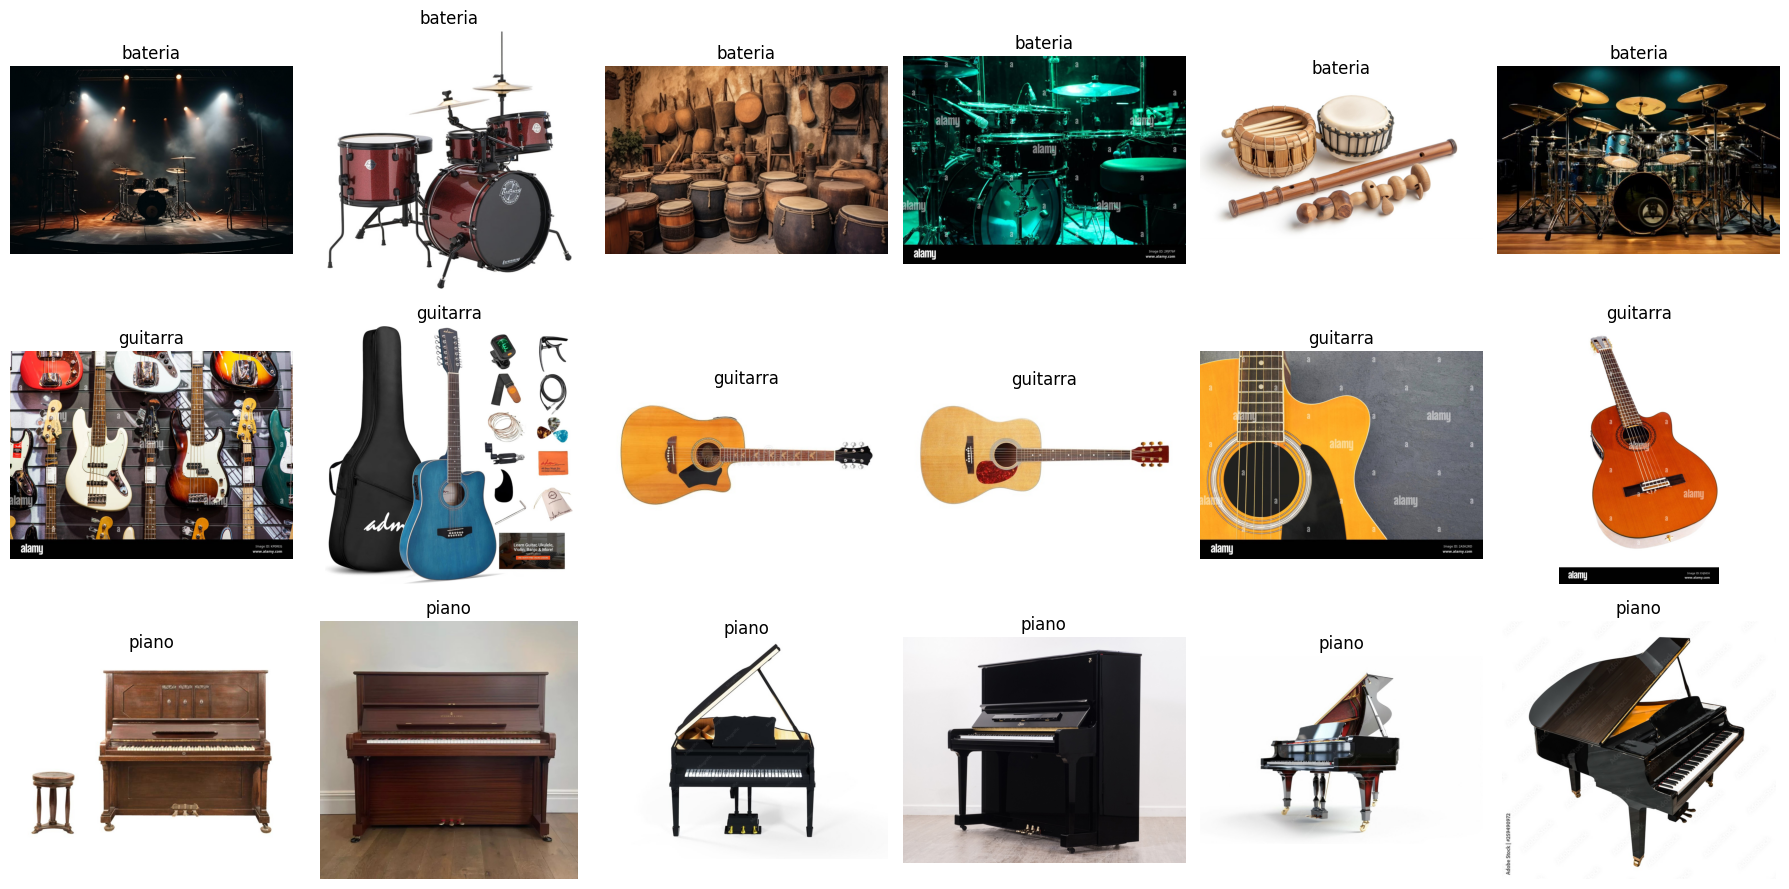

In [14]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

### Registro del dataset

- Imágenes eliminadas por fallo técnico: **0**.
- Conteo descargado: batería **122**, guitarra **102**, piano **101**.
- División final: entrenamiento **226** imágenes; validación **48**; prueba **51**.
- La distribución está razonablemente balanceada, aunque batería tiene más imágenes que las otras clases.
- La comprobación automática confirmó que las imágenes se pueden abrir. La calidad semántica (etiquetas correctas, duplicados, fondos o estilos sesgados) requiere inspección visual y no puede concluirse únicamente a partir de ese conteo.


# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [15]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bateria': 85, 'guitarra': 71, 'piano': 70}
validation {'bateria': 18, 'guitarra': 15, 'piano': 15}
test {'bateria': 19, 'guitarra': 16, 'piano': 16}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:** si se usa repetidamente el conjunto de prueba para elegir épocas, la tasa de aprendizaje o cuántas capas descongelar, las decisiones empiezan a adaptarse indirectamente a ese conjunto. Aunque no se entrenen los pesos directamente con sus etiquetas, se está usando su resultado para optimizar el modelo. Por eso la métrica deja de ser una evaluación independiente y puede sobreestimar la generalización. Las decisiones deben tomarse con entrenamiento y validación; el conjunto de prueba se reserva para la evaluación final.


# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [16]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 226 files belonging to 3 classes.
Found 48 files belonging to 3 classes.
Found 51 files belonging to 3 classes.
['bateria', 'guitarra', 'piano']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [17]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

In [18]:
# TODO 3 — Transfer learning con EfficientNetB0 congelada
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.6018 - loss: 0.9015 - val_accuracy: 1.0000 - val_loss: 0.5041
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.9513 - loss: 0.4258 - val_accuracy: 1.0000 - val_loss: 0.2389
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 45s 3s/step - accuracy: 0.9956 - loss: 0.1942 - val_accuracy: 1.0000 - val_loss: 0.1400
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 1.0000 - loss: 0.1161 - val_accuracy: 0.9792 - val_loss: 0.0978
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.9912 - loss: 0.0820 - val_accuracy: 0.9792 - val_loss: 0.0761
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9956 - loss: 0.0649 - val_accuracy: 0.9792 - val_loss: 0.0648
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 1.0000 - loss: 0.0429 - val_accuracy: 0.9792 - val_loss: 0.0577
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 1.0000 - loss: 0.0369 - val_accuracy: 0.9792 - val_loss: 0.0532
Epoch 9/

### Predicción antes de entrenar

Como la cabeza de clasificación comienza con pesos nuevos, espero que `train_accuracy` aumente durante las primeras épocas a medida que aprende a asociar las características de EfficientNet con las tres clases. Una señal de sobreajuste sería que `train_accuracy` siga subiendo mientras `val_accuracy` se estanca o baja y `val_loss` aumenta.

### Resultado observado

La accuracy de entrenamiento subió rápidamente: aproximadamente **0.602 en la época 1**, **0.951 en la época 2** y llegó a valores cercanos a **1.000**. La accuracy de validación fue **1.000 durante las primeras tres épocas** y luego se mantuvo en **0.9792**. La pérdida de validación continuó disminuyendo hasta **0.0477** en la época 10. Esto no muestra un deterioro claro de la pérdida de validación; sí hay una pequeña diferencia entre entrenamiento casi perfecto y validación de 97.92%, que conviene vigilar por posible sobreajuste leve.


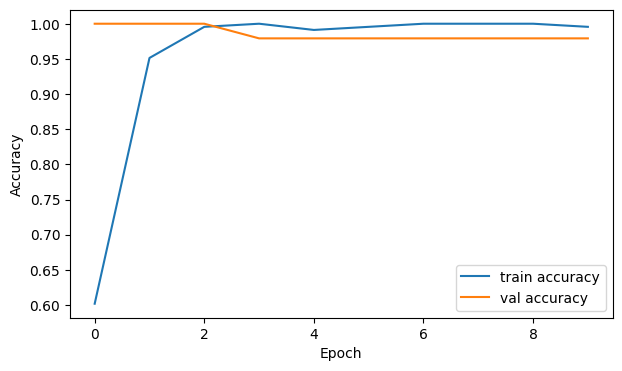

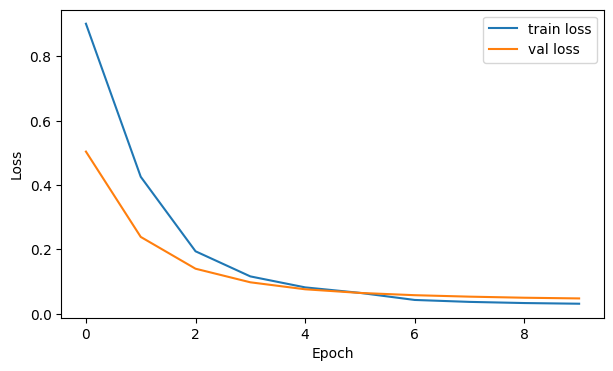

In [19]:
# Curvas de accuracy y loss del entrenamiento con base congelada
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [20]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


              precision    recall  f1-score   support

     bateria      1.000     1.000     1.000        19
    guitarra      1.000     1.000     1.000        16
       piano      1.000     1.000     1.000        16

    accuracy                          1.000        51
   macro avg      1.000     1.000     1.000        51
weighted avg      1.000     1.000     1.000        51



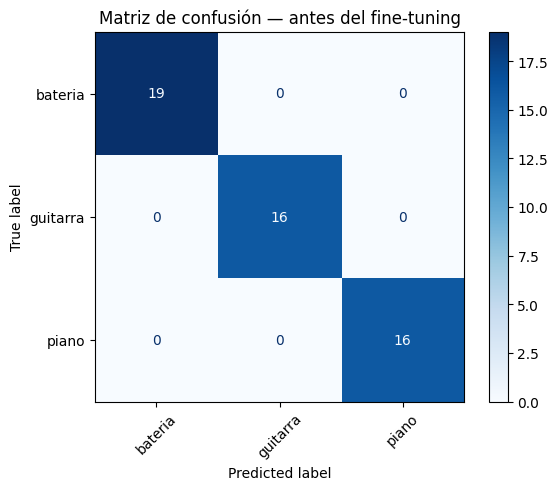

In [21]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — Interpretación de la evaluación inicial

La respuesta definitiva depende de las métricas y la matriz de confusión que produzca tu ejecución. Usa el siguiente criterio:

1. **Mejor clase:** revisa el F1-score por clase (y precision/recall); la clase con F1 más alto suele tener el equilibrio más sólido.
2. **Confusión principal:** busca el mayor valor fuera de la diagonal de la matriz. Las filas representan la clase real y las columnas la predicción.
3. **Accuracy global:** sí puede ocultar problemas si una clase tiene peor recall/F1, especialmente si hay distinto número de imágenes por clase. Por eso revisamos métricas por clase.
4. **Primera mejora del dataset:** quitar etiquetas incorrectas y ejemplos ambiguos; luego equilibrar cantidades y diversificar fondos, ángulos, tamaños y condiciones de luz.

No es posible afirmar de antemano qué clase será la mejor ni cuál será la confusión más frecuente: eso debe salir de los resultados reales.

### Respuesta basada en la evaluación inicial

- **Mejor clase:** las tres clases empataron. Batería, guitarra y piano obtuvieron precision = **1.000**, recall = **1.000** y F1-score = **1.000**.
- **Confusión principal:** no hubo confusiones en el conjunto de prueba; las 51 imágenes se clasificaron correctamente. La matriz de confusión tiene todos sus valores en la diagonal.
- **Accuracy global:** fue **1.000 (100%)**. En este experimento coincide con las métricas por clase, en parte porque el conjunto está relativamente balanceado (19 baterías, 16 guitarras y 16 pianos). Aun así, un resultado perfecto en un test pequeño no garantiza el mismo rendimiento en imágenes externas.
- **Mejora del dataset:** pese al resultado, conviene revisar manualmente etiquetas y duplicados y procurar diversidad de fondos, ángulos, iluminación y tipos de instrumento. También sería útil evaluar con un conjunto externo independiente para comprobar la generalización.


# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [22]:
base_model.trainable = True

# Descongelamos las últimas 20 capas para permitir una adaptación moderada.
# Es una decisión inicial razonable para un dataset relativamente pequeño.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado para evitar cambios inestables
# en sus estadísticas con un dataset pequeño.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

### Decisión y resultado

Se descongelaron las últimas **20 capas** de EfficientNetB0; debido a que las capas Batch Normalization se mantuvieron congeladas, quedaron **15 capas entrenables de la base sobre 238**. Esta adaptación parcial limita los cambios en la red preentrenada y es prudente para un dataset pequeño. Se usó `Adam` con `learning_rate=1e-5` y un máximo de 5 épocas, dentro del rango recomendado. La accuracy de validación se mantuvo en **0.9792** durante las cinco épocas y `val_loss` mejoró de **0.0442 a 0.0379**, por lo que no se observó un empeoramiento en validación.


In [23]:
# TODO 5 — Fine-tuning con learning rate pequeño
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping_ft],
)

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 1.0000 - loss: 0.0240 - val_accuracy: 0.9792 - val_loss: 0.0442
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9956 - loss: 0.0281 - val_accuracy: 0.9792 - val_loss: 0.0414
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 1.0000 - loss: 0.0183 - val_accuracy: 0.9792 - val_loss: 0.0394
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9956 - loss: 0.0215 - val_accuracy: 0.9792 - val_loss: 0.0386
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 1.0000 - loss: 0.0118 - val_accuracy: 0.9792 - val_loss: 0.0379


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [24]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 1.0000
Después del fine-tuning: 1.0000
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bateria      1.000     1.000     1.000        19
    guitarra      1.000     1.000     1.000        16
       piano      1.000     1.000     1.000        16

    accuracy                          1.000        51
   macro avg      1.000     1.000     1.000        51
weighted avg      1.000     1.000     1.000        51



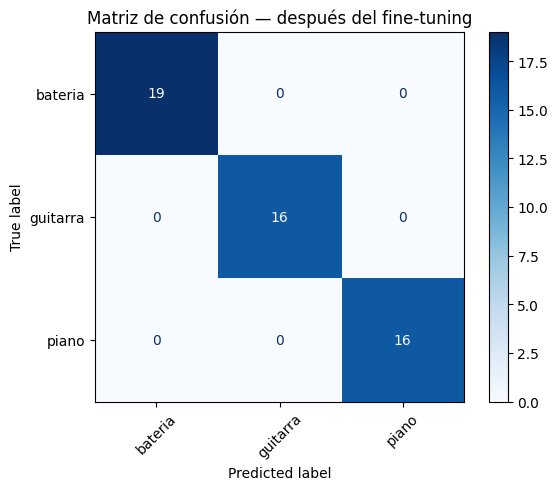

In [25]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# Analiza los errores del modelo después del fine-tuning.
# Las imágenes que se muestran deben inspeccionarse visualmente para asignar
# una causa probable; no se debe inferir una causa solo por la etiqueta.

In [26]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))

    random.shuffle(mistakes)
    selected = mistakes[:max_images]
    if not selected:
        print("No se encontraron errores en este conjunto.")
        return mistakes

    cols = 4
    rows = int(np.ceil(len(selected) / cols))
    plt.figure(figsize=(16, 4 * rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(selected):
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return mistakes

mistakes_ft = show_mistakes(test_ds, model, class_names, max_images=12)
print(f"Errores encontrados en test: {len(mistakes_ft)}")
print("Inspecciona visualmente los ejemplos antes de decidir la causa probable.")

No se encontraron errores en este conjunto.
Errores encontrados en test: 0
Inspecciona visualmente los ejemplos antes de decidir la causa probable.


In [27]:
# Tabla de los primeros cinco errores reales para completar tras inspeccionar las imágenes.
import pandas as pd

if mistakes_ft:
    error_rows = []
    for i, (_, true_label, pred_label, confidence) in enumerate(mistakes_ft[:5], start=1):
        error_rows.append({
            "Imagen/error": i,
            "Clase real": class_names[true_label],
            "Predicción": class_names[pred_label],
            "Confianza de la predicción": round(confidence, 3),
            "Causa probable (completar tras inspección)": "",
            "¿Cómo lo mejoraría? (completar)": "",
        })
    display(pd.DataFrame(error_rows))
else:
    print("No hay errores para tabular en este conjunto; registra este resultado y revisa otras particiones solo como análisis adicional.")

No hay errores para tabular en este conjunto; registra este resultado y revisa otras particiones solo como análisis adicional.


## TODO 6 — Análisis de errores y conclusiones

### Análisis de errores observado

Después del fine-tuning, el modelo no cometió errores en el conjunto de prueba: clasificó correctamente las **51 imágenes** (19 de batería, 16 de guitarra y 16 de piano). Por lo tanto, no existen cinco errores reales que se puedan inspeccionar en este conjunto. No sería correcto inventar ejemplos o causas. La tabla de errores quedó vacía porque no hubo predicciones incorrectas.

Como siguiente paso, se recomienda probar imágenes externas que no pertenezcan al dataset, idealmente con fondos, ángulos, iluminación y tipos de instrumentos distintos. Si aparecen errores en esa evaluación, se deben registrar la clase real, la predicción, lo observado y una causa probable.

### Conclusión con los resultados obtenidos

- **Construcción del dataset:** se descargaron 325 imágenes en total: 122 de batería, 102 de guitarra y 101 de piano. La descarga se interrumpió durante una consulta, pero el dataset conservó ejemplos de las tres clases.
- **Validación:** se eliminaron 0 imágenes por problemas de decodificación. Esta prueba confirma que los archivos pueden leerse, pero no certifica por sí sola que todas las etiquetas sean correctas.
- **Separación:** quedaron 226 imágenes de entrenamiento, 48 de validación y 51 de prueba.
- **Desempeño inicial:** la accuracy de test antes del fine-tuning fue **100%**. Las métricas precision, recall y F1 fueron 1.000 para las tres clases.
- **Cambio después del fine-tuning:** la accuracy de test se mantuvo en **100%**. La diferencia fue **0.0000**, es decir, no hubo mejora medible en accuracy de test. La pérdida de validación sí bajó durante el fine-tuning, de 0.0442 a 0.0379 en las épocas registradas.
- **¿Ayudó el fine-tuning?:** no aumentó la accuracy de test porque ya era perfecta antes; sí redujo la pérdida de validación. Con solo 51 imágenes de prueba, el resultado debe interpretarse con cautela y comprobarse con imágenes externas.
- **Qué mejorar primero:** revisar manualmente las etiquetas y duplicados, aumentar la variedad de imágenes y probar con un conjunto independiente más diverso. Esto permite comprobar si el rendimiento perfecto refleja aprendizaje generalizable y no similitudes particulares del dataset.

### Diferencia conceptual

- **Feature extraction / transfer learning con base congelada:** EfficientNetB0 comienza con pesos aprendidos previamente en ImageNet. Esos pesos se mantienen fijos y solo se entrenan los parámetros de la nueva cabeza de clasificación para distinguir piano, batería y guitarra.
- **Fine-tuning:** se descongela una parte de EfficientNet y se actualizan algunos de sus pesos, además de los de la cabeza, usando una tasa de aprendizaje pequeña. Así las características preentrenadas se adaptan a las imágenes del nuevo problema.
- **CNN desde cero:** los pesos de la red comienzan sin el conocimiento preentrenado de ImageNet y se aprenden usando el dataset propio. Normalmente necesita más datos y entrenamiento, y con un conjunto pequeño puede generalizar peor.


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [ ]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

**Feature extraction / transfer learning con base congelada:** se aprovecha una red que ya aprendió características visuales a partir de ImageNet. Se congelan sus capas y solo se entrena la cabeza nueva que aprende a clasificar las tres clases del taller.

**Fine-tuning:** se permite que algunas capas finales de la red preentrenada también actualicen sus pesos. Se utiliza una tasa de aprendizaje pequeña para adaptar las características existentes al nuevo conjunto sin modificar demasiado lo que la red ya aprendió.

**Entrenar una CNN desde cero:** no se parte de pesos preentrenados; los parámetros de la red se aprenden con las imágenes del taller. Esto suele requerir más datos y recursos para alcanzar un desempeño comparable.

**En este taller:** la accuracy de prueba fue 100% antes y después del fine-tuning, así que no hubo una mejora medible en accuracy. La pérdida de validación sí disminuyó durante el fine-tuning. Como el conjunto de prueba tiene 51 imágenes, sería importante probar con imágenes externas antes de concluir que el modelo generaliza perfectamente.


# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |